### Load Dataset and Initial Inspection

First, we'll load the `logistics_supply_chain_dataset.csv` file into a pandas DataFrame and display the first few rows to understand its structure and content.

In [1]:
import pandas as pd

# Load the dataset from the specified path
df = pd.read_csv('/content/logistics_supply_chain_dataset.csv')

# Display the first 5 rows of the DataFrame to inspect the data
display(df.head())

,Shipment_ID,Origin,Destination,Warehouse,Pickup_Time,Sorting_Time,Dispatch_Time,Delivery_Time,Transit_Time,Transport_Mode,Delivery_Status,Shipment_Volume
0,SHP00001,Hyderabad,Bengaluru,Bengaluru Distribution Center,2026-01-20 12:09:00,2026-01-21 01:42:31,2026-01-21 07:10:09,2026-01-23 09:38:06,69.49,Road,Delayed,38
1,SHP00002,Coimbatore,Mumbai,Chennai Central Hub,2026-01-09 10:32:00,2026-01-10 02:01:57,2026-01-10 08:51:21,2026-01-11 12:40:06,50.14,Rail,Delayed,68
2,SHP00003,Chennai,Bengaluru,Chennai Central Hub,2026-04-21 04:36:00,2026-04-21 12:06:56,2026-04-21 15:00:08,2026-04-22 20:37:39,40.03,Rail,On Time,40
3,SHP00004,Madurai,Kochi,Bengaluru Distribution Center,2026-05-30 05:50:00,2026-05-30 12:14:50,2026-05-30 15:35:38,2026-06-01 10:32:38,52.71,Rail,On Time,47
4,SHP00005,Madurai,Coimbatore,Mumbai Logistics Hub,2026-01-24 00:52:00,2026-01-24 09:02:55,2026-01-24 16:39:48,2026-01-27 00:58:32,72.11,Road,Delayed,70


### Data Cleaning: Removing Duplicate Records

First, we will check for any duplicate rows in the dataset and remove them to ensure data integrity.

In [2]:
# Check for duplicate records
duplicates_before = df.duplicated().sum()
print(f"Number of duplicate records before removal: {duplicates_before}")

# Remove duplicate records
df.drop_duplicates(inplace=True)

duplicates_after = df.duplicated().sum()
print(f"Number of duplicate records after removal: {duplicates_after}")
print(f"DataFrame shape after removing duplicates: {df.shape}")

Number of duplicate records before removal: 5
Number of duplicate records after removal: 0
DataFrame shape after removing duplicates: (1800, 12)


### Data Cleaning: Handling Missing Values

Now, we will identify any missing values in the dataset and determine how to handle them. Depending on the extent and nature of missingness, we might fill them or remove rows/columns.

In [3]:
# Check for missing values
missing_values = df.isnull().sum()
missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_info = pd.DataFrame({
    'Missing Values': missing_values,
    'Percentage': missing_percentage
})

print("Missing values before handling:")
display(missing_info[missing_info['Missing Values'] > 0])

# Handle missing values: For simplicity, we'll fill numerical columns with their median
# and categorical columns with their mode.
# However, it's important to analyze each column's missingness pattern individually in a real project.

# Identify numerical and categorical columns
numerical_cols = df.select_dtypes(include=['number']).columns
categorical_cols = df.select_dtypes(include=['object']).columns

for col in numerical_cols:
    if df[col].isnull().any():
        median_val = df[col].median()
        df[col].fillna(median_val, inplace=True)
        print(f"Filled missing values in numerical column '{col}' with median: {median_val}")

for col in categorical_cols:
    if df[col].isnull().any():
        mode_val = df[col].mode()[0] # .mode() can return multiple values, take the first one
        df[col].fillna(mode_val, inplace=True)
        print(f"Filled missing values in categorical column '{col}' with mode: {mode_val}")

# Verify that there are no more missing values
print("\nMissing values after handling:")
display(df.isnull().sum().to_frame(name='Missing Values'))

Missing values before handling:


,Missing Values,Percentage
Warehouse,14,0.777778
Transit_Time,9,0.500000
Transport_Mode,10,0.555556


Filled missing values in numerical column 'Transit_Time' with median: 47.24
Filled missing values in categorical column 'Warehouse' with mode: Chennai Central Hub
Filled missing values in categorical column 'Transport_Mode' with mode: Road

Missing values after handling:


/tmp/ipykernel_744/1145646651.py:24: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(median_val, inplace=True)
/tmp/ipykernel_744/1145646651.py:30: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'd

,Missing Values
Shipment_ID,0
Origin,0
Destination,0
Warehouse,0
Pickup_Time,0
Sorting_Time,0
Dispatch_Time,0
Delivery_Time,0
Transit_Time,0
Transport_Mode,0


### Data Cleaning: Validate Timestamps

We need to convert timestamp columns to datetime objects and then validate their chronological order to ensure data quality. Records with illogical timestamp sequences will be identified and addressed.

In [4]:
# Convert timestamp columns to datetime objects
timestamp_cols = ['Pickup_Time', 'Sorting_Time', 'Dispatch_Time', 'Delivery_Time']
for col in timestamp_cols:
    df[col] = pd.to_datetime(df[col], errors='coerce') # 'coerce' will turn unparseable dates into NaT

# Check for any NaT values introduced by coercion (unparseable dates)
print("Number of unparseable dates (NaT values) after conversion:")
display(df[timestamp_cols].isnull().sum().to_frame(name='NaT Values'))

# Drop rows with NaT values in timestamp columns, as these records are fundamentally flawed
initial_rows = len(df)
df.dropna(subset=timestamp_cols, inplace=True)
dropped_rows = initial_rows - len(df)
print(f"Dropped {dropped_rows} rows due to unparseable or missing timestamp values.")

# Validate chronological order: Pickup_Time <= Sorting_Time <= Dispatch_Time <= Delivery_Time
invalid_timestamp_order = df[~(
    (df['Pickup_Time'] <= df['Sorting_Time']) &
    (df['Sorting_Time'] <= df['Dispatch_Time']) &
    (df['Dispatch_Time'] <= df['Delivery_Time'])
)]

print(f"\nNumber of records with invalid chronological timestamp order: {len(invalid_timestamp_order)}")

# How to handle invalid records: For now, we'll remove them as they indicate severely corrupted data.
# In a real-world scenario, further investigation or imputation might be considered.
if not invalid_timestamp_order.empty:
    print(f"Removing {len(invalid_timestamp_order)} records with invalid timestamp order.")
    df.drop(invalid_timestamp_order.index, inplace=True)
    print(f"Remaining rows after removing invalid timestamp order records: {len(df)}")
else:
    print("No records found with invalid chronological timestamp order.")

print(f"\nDataFrame shape after timestamp validation: {df.shape}")

Number of unparseable dates (NaT values) after conversion:


,NaT Values
Pickup_Time,0
Sorting_Time,0
Dispatch_Time,0
Delivery_Time,0


Dropped 0 rows due to unparseable or missing timestamp values.

Number of records with invalid chronological timestamp order: 0
No records found with invalid chronological timestamp order.

DataFrame shape after timestamp validation: (1800, 12)


### Calculate Stage Durations

We will now calculate the duration for each logistics stage in hours: 'Pickup to Sorting', 'Sorting to Dispatch', and 'Dispatch to Delivery'. These durations are crucial for understanding the efficiency of each part of the supply chain.

In [5]:
# Calculate duration for 'Pickup to Sorting' in hours
df['Duration_Pickup_to_Sorting_Hours'] = (df['Sorting_Time'] - df['Pickup_Time']).dt.total_seconds() / 3600

# Calculate duration for 'Sorting to Dispatch' in hours
df['Duration_Sorting_to_Dispatch_Hours'] = (df['Dispatch_Time'] - df['Sorting_Time']).dt.total_seconds() / 3600

# Calculate duration for 'Dispatch to Delivery' in hours
df['Duration_Dispatch_to_Delivery_Hours'] = (df['Delivery_Time'] - df['Dispatch_Time']).dt.total_seconds() / 3600

# Display the first few rows with the new duration columns
print("DataFrame with calculated stage durations:")
display(df[['Pickup_Time', 'Sorting_Time', 'Dispatch_Time', 'Delivery_Time',
            'Duration_Pickup_to_Sorting_Hours', 'Duration_Sorting_to_Dispatch_Hours',
            'Duration_Dispatch_to_Delivery_Hours']].head())

DataFrame with calculated stage durations:


,Pickup_Time,Sorting_Time,Dispatch_Time,Delivery_Time,Duration_Pickup_to_Sorting_Hours,Duration_Sorting_to_Dispatch_Hours,Duration_Dispatch_to_Delivery_Hours
0,2026-01-20 12:09:00,2026-01-21 01:42:31,2026-01-21 07:10:09,2026-01-23 09:38:06,13.558611,5.460556,50.465833
1,2026-01-09 10:32:00,2026-01-10 02:01:57,2026-01-10 08:51:21,2026-01-11 12:40:06,15.499167,6.823333,27.812500
2,2026-04-21 04:36:00,2026-04-21 12:06:56,2026-04-21 15:00:08,2026-04-22 20:37:39,7.515556,2.886667,29.625278
3,2026-05-30 05:50:00,2026-05-30 12:14:50,2026-05-30 15:35:38,2026-06-01 10:32:38,6.413889,3.346667,42.950000
4,2026-01-24 00:52:00,2026-01-24 09:02:55,2026-01-24 16:39:48,2026-01-27 00:58:32,8.181944,7.614722,56.312222


### Compare Calculated Total Transit Duration with `Transit_Time` Column

We will now calculate the total transit time from our newly computed stage durations and compare it with the `Transit_Time` column provided in the dataset. This comparison will help us identify any discrepancies and understand data consistency.

In [6]:
# Calculate total transit duration from the sum of stage durations
df['Calculated_Total_Transit_Time'] = df['Duration_Pickup_to_Sorting_Hours'] + \
                                     df['Duration_Sorting_to_Dispatch_Hours'] + \
                                     df['Duration_Dispatch_to_Delivery_Hours']

# Calculate the difference between the given Transit_Time and the calculated total transit time
df['Transit_Time_Discrepancy'] = df['Transit_Time'] - df['Calculated_Total_Transit_Time']

# Display the first few rows with the new columns for comparison
print("Comparison of Transit_Time and Calculated_Total_Transit_Time:")
display(df[['Transit_Time', 'Calculated_Total_Transit_Time', 'Transit_Time_Discrepancy']].head())

# Analyze discrepancies
print("\nSummary of Transit_Time_Discrepancy:")
display(df['Transit_Time_Discrepancy'].describe())

# Count records with significant discrepancies (e.g., absolute difference > 1 hour)
significant_discrepancies = df[abs(df['Transit_Time_Discrepancy']) > 1]
print(f"\nNumber of records with significant transit time discrepancies (abs > 1 hour): {len(significant_discrepancies)}")

if not significant_discrepancies.empty:
    print("\nExamples of significant discrepancies:")
    display(significant_discrepancies[['Pickup_Time', 'Delivery_Time', 'Transit_Time', 'Calculated_Total_Transit_Time', 'Transit_Time_Discrepancy']].head())

# Handling discrepancies: For this project, we will use the 'Calculated_Total_Transit_Time'
# as it is derived directly from the validated timestamps, assuming it's more reliable.
# In a real-world scenario, these discrepancies would warrant further investigation
# with the data source owner to understand the cause (e.g., different calculation methods,
# rounding, data entry errors).
print("\nNote: For further analysis, 'Calculated_Total_Transit_Time' will be used.")

Comparison of Transit_Time and Calculated_Total_Transit_Time:


,Transit_Time,Calculated_Total_Transit_Time,Transit_Time_Discrepancy
0,69.49,69.485000,0.005000
1,50.14,50.135000,0.005000
2,40.03,40.027500,0.002500
3,52.71,52.710556,-0.000556
4,72.11,72.108889,0.001111



Summary of Transit_Time_Discrepancy:


,Transit_Time_Discrepancy
count,1800.000000
mean,0.022718
std,0.872632
min,-17.996111
25%,-0.002222
50%,0.000278
75%,0.002778
max,22.297778



Number of records with significant transit time discrepancies (abs > 1 hour): 9

Examples of significant discrepancies:


,Pickup_Time,Delivery_Time,Transit_Time,Calculated_Total_Transit_Time,Transit_Time_Discrepancy
46,2026-04-23 22:21:00,2026-04-25 09:23:50,47.24,35.047222,12.192778
61,2026-03-19 21:48:00,2026-03-21 18:15:36,47.24,44.460000,2.780000
403,2026-04-18 23:49:00,2026-04-21 06:23:07,47.24,54.568611,-7.328611
451,2026-01-12 05:49:00,2026-01-13 18:15:28,47.24,36.441111,10.798889
651,2026-01-07 05:24:00,2026-01-08 17:17:52,47.24,35.897778,11.342222



Note: For further analysis, 'Calculated_Total_Transit_Time' will be used.


### Analyze Average Stage Durations, Total Transit Time and Delivery Status

This section will focus on understanding the key performance indicators of the logistics process by analyzing the average duration of each stage, the total transit time, and the delivery status distribution. This will provide insights into the overall efficiency and potential areas for improvement.

In [7]:
# Calculate average duration for each stage
avg_pickup_to_sorting = df['Duration_Pickup_to_Sorting_Hours'].mean()
avg_sorting_to_dispatch = df['Duration_Sorting_to_Dispatch_Hours'].mean()
avg_dispatch_to_delivery = df['Duration_Dispatch_to_Delivery_Hours'].mean()

print(f"Average Pickup to Sorting Duration: {avg_pickup_to_sorting:.2f} hours")
print(f"Average Sorting to Dispatch Duration: {avg_sorting_to_dispatch:.2f} hours")
print(f"Average Dispatch to Delivery Duration: {avg_dispatch_to_delivery:.2f} hours")

# Analyze total transit time
print("\nSummary Statistics for Total Transit Time:")
display(df['Calculated_Total_Transit_Time'].describe())

# Analyze Delivery Status distribution
print("\nDelivery Status Distribution:")
delivery_status_counts = df['Delivery_Status'].value_counts()
delivery_status_percentage = df['Delivery_Status'].value_counts(normalize=True) * 100
display(pd.DataFrame({'Count': delivery_status_counts, 'Percentage': delivery_status_percentage}))

Average Pickup to Sorting Duration: 10.51 hours
Average Sorting to Dispatch Duration: 4.98 hours
Average Dispatch to Delivery Duration: 33.71 hours

Summary Statistics for Total Transit Time:


,Calculated_Total_Transit_Time
count,1800.000000
mean,49.189910
std,14.880190
min,15.310278
25%,38.002708
50%,47.123889
75%,58.775903
max,99.666944



Delivery Status Distribution:


,Count,Percentage
Delivery_Status,,
Delayed,908,50.444444
On Time,892,49.555556


### Identify Warehouses with High Processing Times and Delayed-Shipment Rates

This section will identify which warehouses are experiencing high processing times (sum of pickup to sorting and sorting to dispatch durations) and high rates of delayed shipments. This analysis can help pinpoint specific operational issues at individual warehouses.

In [8]:
# Calculate processing time for each shipment (Pickup to Dispatch)
df['Processing_Time_Hours'] = df['Duration_Pickup_to_Sorting_Hours'] + df['Duration_Sorting_to_Dispatch_Hours']

# Group by Warehouse to find average processing time
warehouse_processing_time = df.groupby('Warehouse')['Processing_Time_Hours'].mean().sort_values(ascending=False)

print("Warehouses with highest average processing times (Pickup to Dispatch):")
display(warehouse_processing_time)

# Calculate delayed shipment rate for each warehouse
warehouse_delay_rate = df.groupby('Warehouse')['Delivery_Status'].apply(lambda x: (x == 'Delayed').sum() / len(x) * 100).sort_values(ascending=False)

print("\nWarehouses with highest delayed shipment rates:")
display(warehouse_delay_rate)

Warehouses with highest average processing times (Pickup to Dispatch):


,Processing_Time_Hours
Warehouse,
Mumbai Logistics Hub,17.289384
Bengaluru Distribution Center,15.833686
Pune Transit Center,15.766568
Hyderabad Sorting Hub,15.165596
Chennai Central Hub,15.146082
Coimbatore Regional Hub,13.621702



Warehouses with highest delayed shipment rates:


,Delivery_Status
Warehouse,
Mumbai Logistics Hub,54.333333
Pune Transit Center,52.127660
Bengaluru Distribution Center,51.933702
Hyderabad Sorting Hub,50.184502
Chennai Central Hub,49.394673
Coimbatore Regional Hub,44.736842


### Compare Road, Rail, and Air Transport Modes

This section will compare the different transport modes based on their average total transit time and delayed shipment rates. This analysis will help in understanding the efficiency and reliability of each mode.

In [9]:
# Group by Transport_Mode to find average total transit time
transport_mode_transit_time = df.groupby('Transport_Mode')['Calculated_Total_Transit_Time'].mean().sort_values(ascending=False)

print("Average Total Transit Time by Transport Mode (hours):")
display(transport_mode_transit_time)

# Calculate delayed shipment rate for each transport mode
transport_mode_delay_rate = df.groupby('Transport_Mode')['Delivery_Status'].apply(lambda x: (x == 'Delayed').sum() / len(x) * 100).sort_values(ascending=False)

print("\nDelayed Shipment Rate by Transport Mode (%):")
display(transport_mode_delay_rate)

# Further compare average stage durations by transport mode
print("\nAverage Stage Durations by Transport Mode (hours):")
stage_durations_by_mode = df.groupby('Transport_Mode')[[
    'Duration_Pickup_to_Sorting_Hours',
    'Duration_Sorting_to_Dispatch_Hours',
    'Duration_Dispatch_to_Delivery_Hours'
]].mean()
display(stage_durations_by_mode)

Average Total Transit Time by Transport Mode (hours):


,Calculated_Total_Transit_Time
Transport_Mode,
Road,54.440265
Rail,46.380411
Air,34.586342



Delayed Shipment Rate by Transport Mode (%):


,Delivery_Status
Transport_Mode,
Road,61.425781
Rail,44.158416
Air,20.664207



Average Stage Durations by Transport Mode (hours):


,Duration_Pickup_to_Sorting_Hours,Duration_Sorting_to_Dispatch_Hours,Duration_Dispatch_to_Delivery_Hours
Transport_Mode,,,
Air,10.465473,4.634648,19.486221
Rail,10.503613,4.587639,31.289159
Road,10.522697,5.256687,38.660881


### Investigate Relationship Between Shipment_Volume and Processing Time

This section will explore how `Shipment_Volume` relates to the `Sorting_Time` and `Dispatch_Time` stages. We will analyze if larger shipment volumes lead to longer processing times at these critical logistics points.

Correlation between Shipment_Volume and Sorting/Dispatch Processing Times:
Correlation between Shipment_Volume and Sorting_Processing_Time_Hours: 0.45
Correlation between Shipment_Volume and Dispatch_Processing_Time_Hours: 0.37


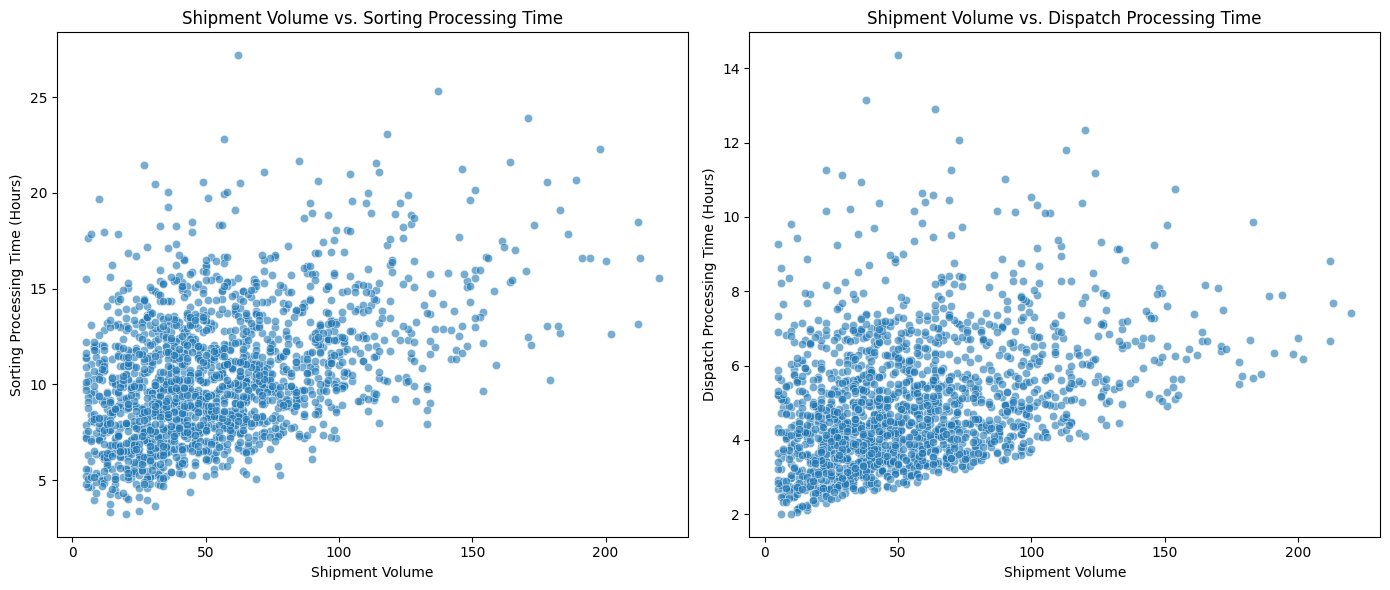

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate sorting processing time and dispatch processing time
df['Sorting_Processing_Time_Hours'] = (df['Sorting_Time'] - df['Pickup_Time']).dt.total_seconds() / 3600
df['Dispatch_Processing_Time_Hours'] = (df['Dispatch_Time'] - df['Sorting_Time']).dt.total_seconds() / 3600

print("Correlation between Shipment_Volume and Sorting/Dispatch Processing Times:")

# Correlation with Sorting Processing Time
sorting_correlation = df['Shipment_Volume'].corr(df['Sorting_Processing_Time_Hours'])
print(f"Correlation between Shipment_Volume and Sorting_Processing_Time_Hours: {sorting_correlation:.2f}")

# Correlation with Dispatch Processing Time
dispatch_correlation = df['Shipment_Volume'].corr(df['Dispatch_Processing_Time_Hours'])
print(f"Correlation between Shipment_Volume and Dispatch_Processing_Time_Hours: {dispatch_correlation:.2f}")

# Visualize the relationship using scatter plots
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
sns.scatterplot(x='Shipment_Volume', y='Sorting_Processing_Time_Hours', data=df, alpha=0.6)
plt.title('Shipment Volume vs. Sorting Processing Time')
plt.xlabel('Shipment Volume')
plt.ylabel('Sorting Processing Time (Hours)')

plt.subplot(1, 2, 2)
sns.scatterplot(x='Shipment_Volume', y='Dispatch_Processing_Time_Hours', data=df, alpha=0.6)
plt.title('Shipment Volume vs. Dispatch Processing Time')
plt.xlabel('Shipment Volume')
plt.ylabel('Dispatch Processing Time (Hours)')

plt.tight_layout()
plt.show()

### Main Visualizations: Stage Durations and Delivery Status

To provide a clear overview of the logistics process, we will now visualize two key aspects: the average duration of each stage (Pickup to Sorting, Sorting to Dispatch, Dispatch to Delivery) and the overall distribution of delivery statuses (On Time vs. Delayed).

/tmp/ipykernel_744/4250186323.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=stages, y=durations, palette='viridis')
/tmp/ipykernel_744/4250186323.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=delivery_status_percentage.index, y=delivery_status_percentage.values, palette='magma')


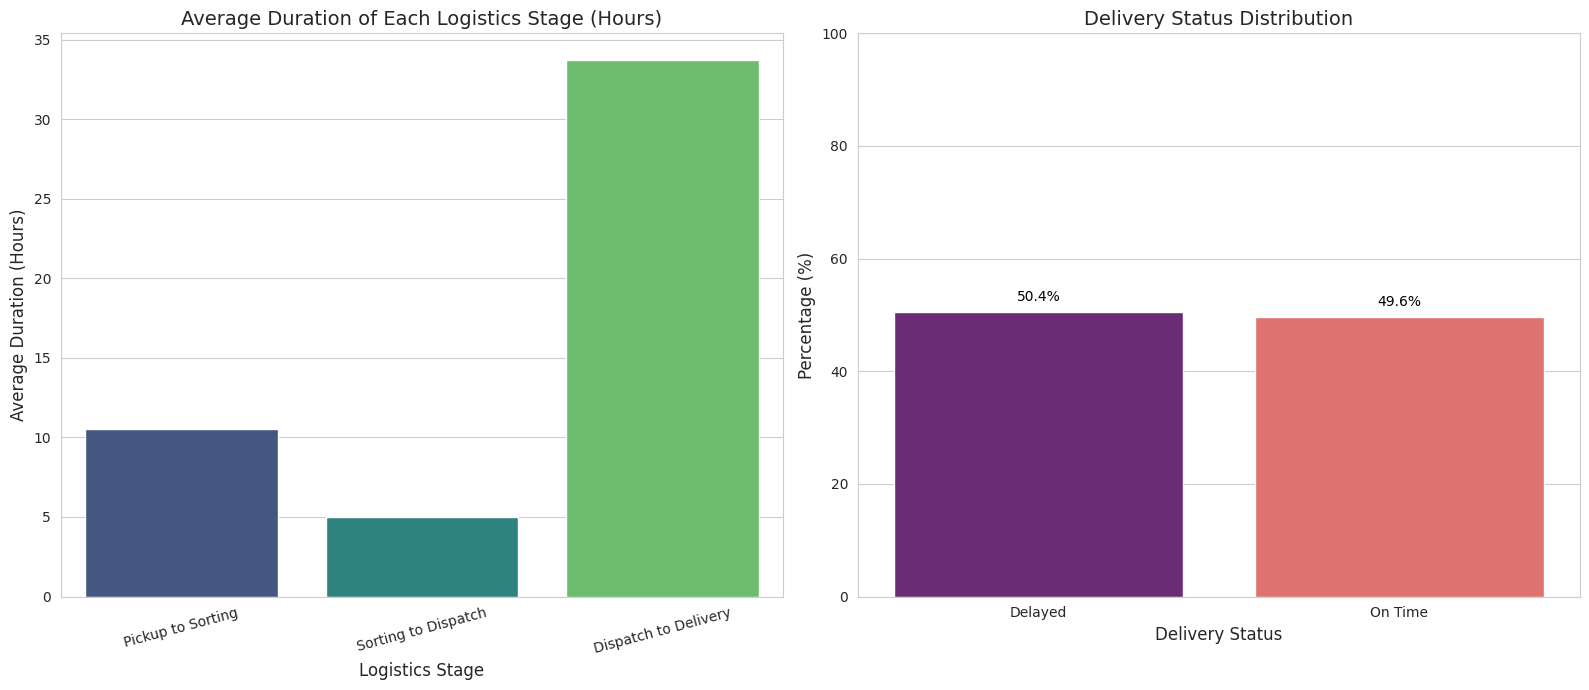

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set aesthetic style for plots
sns.set_style("whitegrid")

plt.figure(figsize=(16, 7))

# --- Visualization 1: Average Stage Durations ---
plt.subplot(1, 2, 1)
stage_durations = {
    'Pickup to Sorting': avg_pickup_to_sorting,
    'Sorting to Dispatch': avg_sorting_to_dispatch,
    'Dispatch to Delivery': avg_dispatch_to_delivery
}
stages = list(stage_durations.keys())
durations = list(stage_durations.values())

sns.barplot(x=stages, y=durations, palette='viridis')
plt.title('Average Duration of Each Logistics Stage (Hours)', fontsize=14)
plt.xlabel('Logistics Stage', fontsize=12)
plt.ylabel('Average Duration (Hours)', fontsize=12)
plt.xticks(rotation=15)

# --- Visualization 2: Delivery Status Distribution ---
plt.subplot(1, 2, 2)
sns.barplot(x=delivery_status_percentage.index, y=delivery_status_percentage.values, palette='magma')
plt.title('Delivery Status Distribution', fontsize=14)
plt.xlabel('Delivery Status', fontsize=12)
plt.ylabel('Percentage (%)', fontsize=12)
plt.ylim(0, 100) # Ensure y-axis goes from 0 to 100

# Add percentage labels on top of bars
for index, row in enumerate(delivery_status_percentage.values):
    plt.text(index, row + 2, f'{row:.1f}%', color='black', ha="center")

plt.tight_layout()
plt.show()

### Process Bottleneck Analysis and Logistics Journey Visualization

To identify critical bottlenecks, we will visualize the entire logistics journey, showing the average time spent in each stage. This will help highlight which stages contribute most significantly to the overall transit time and potential delays.

/tmp/ipykernel_744/2342549364.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Stage', y='Average Duration (Hours)', data=bottleneck_df, palette='rocket')


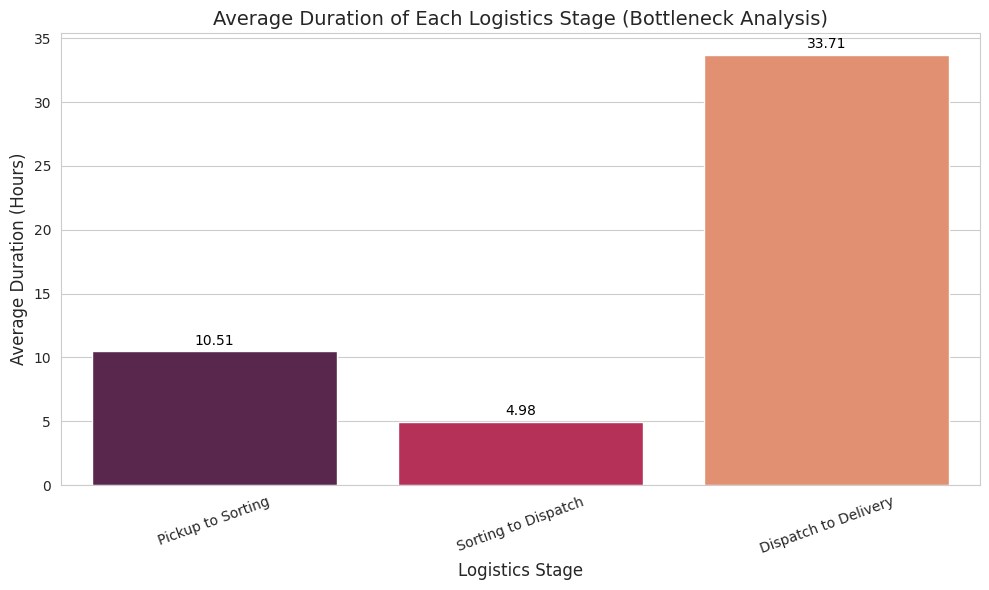


This visualization clearly shows that the 'Dispatch to Delivery' stage is the longest, indicating a potential bottleneck in the last-mile or long-haul delivery process. Further investigation into this stage, considering factors like Transport Mode, Origin, and Destination, would be beneficial.


In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

# Prepare data for bottleneck visualization
stages_bottleneck = ['Pickup to Sorting', 'Sorting to Dispatch', 'Dispatch to Delivery']
durations_bottleneck = [
    df['Duration_Pickup_to_Sorting_Hours'].mean(),
    df['Duration_Sorting_to_Dispatch_Hours'].mean(),
    df['Duration_Dispatch_to_Delivery_Hours'].mean()
]

# Create a DataFrame for easier plotting
bottleneck_df = pd.DataFrame({
    'Stage': stages_bottleneck,
    'Average Duration (Hours)': durations_bottleneck
})

plt.figure(figsize=(10, 6))
sns.barplot(x='Stage', y='Average Duration (Hours)', data=bottleneck_df, palette='rocket')
plt.title('Average Duration of Each Logistics Stage (Bottleneck Analysis)', fontsize=14)
plt.xlabel('Logistics Stage', fontsize=12)
plt.ylabel('Average Duration (Hours)', fontsize=12)
plt.xticks(rotation=20)

# Add labels to the bars
for index, row in bottleneck_df.iterrows():
    plt.text(index, row['Average Duration (Hours)'] + 0.5, f"{row['Average Duration (Hours)']:.2f}", color='black', ha="center")

plt.tight_layout()
plt.show()

print("\nThis visualization clearly shows that the 'Dispatch to Delivery' stage is the longest, indicating a potential bottleneck in the last-mile or long-haul delivery process. Further investigation into this stage, considering factors like Transport Mode, Origin, and Destination, would be beneficial.")

### Predictive Modeling: Random Forest Classifier

We will now build a Random Forest classification model to predict the `Delivery_Status` based on the features extracted and analyzed. This involves several steps:
1.  **Feature Selection**: Choose relevant features from our dataset.
2.  **Categorical Encoding**: Convert categorical variables into a numerical format suitable for machine learning algorithms.
3.  **Data Splitting**: Divide the dataset into training and testing sets.
4.  **Model Training**: Train a Random Forest Classifier on the training data.
5.  **Model Evaluation**: Assess the model's performance using appropriate metrics.
6.  **Feature Importance**: Understand which features contribute most to the predictions.

#### Step 1 & 2: Feature Selection and Categorical Encoding

We will select features that are likely to influence delivery status, including the calculated stage durations, shipment volume, transport mode, and warehouse information. Categorical features will be converted into numerical format using one-hot encoding.

In [13]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score
from sklearn.preprocessing import LabelEncoder

# Define features (X) and target (y)
# Drop original timestamp columns and the calculated discrepancy as they are not direct predictors
# 'Shipment_ID' is an identifier and not a feature
features = [
    'Shipment_Volume',
    'Duration_Pickup_to_Sorting_Hours',
    'Duration_Sorting_to_Dispatch_Hours',
    'Duration_Dispatch_to_Delivery_Hours',
    'Origin',
    'Destination',
    'Warehouse',
    'Transport_Mode'
]

X = df[features]
y = df['Delivery_Status']

# Encode categorical features
X = pd.get_dummies(X, columns=['Origin', 'Destination', 'Warehouse', 'Transport_Mode'], drop_first=True)

# Encode target variable 'Delivery_Status' to numerical (0 for On Time, 1 for Delayed)
le = LabelEncoder()
y_encoded = le.fit_transform(y)

print("Features (X) and Target (y_encoded) prepared for modeling.")
print(f"Shape of X: {X.shape}")
print(f"Shape of y: {y_encoded.shape}")
print("First 5 rows of encoded features (X.head()):")
display(X.head())
print("First 5 rows of encoded target (y_encoded[:5]):")
print(y_encoded[:5])

Features (X) and Target (y_encoded) prepared for modeling.
Shape of X: (1800, 27)
Shape of y: (1800,)
First 5 rows of encoded features (X.head()):


,Shipment_Volume,Duration_Pickup_to_Sorting_Hours,Duration_Sorting_to_Dispatch_Hours,Duration_Dispatch_to_Delivery_Hours,Origin_Chennai,Origin_Coimbatore,Origin_Hyderabad,Origin_Kochi,Origin_Madurai,Origin_Mumbai,...,Destination_Mumbai,Destination_Pune,Destination_Visakhapatnam,Warehouse_Chennai Central Hub,Warehouse_Coimbatore Regional Hub,Warehouse_Hyderabad Sorting Hub,Warehouse_Mumbai Logistics Hub,Warehouse_Pune Transit Center,Transport_Mode_Rail,Transport_Mode_Road
0,38,13.558611,5.460556,50.465833,False,False,True,False,False,False,...,False,False,False,False,False,False,False,False,False,True
1,68,15.499167,6.823333,27.812500,False,True,False,False,False,False,...,True,False,False,True,False,False,False,False,True,False
2,40,7.515556,2.886667,29.625278,True,False,False,False,False,False,...,False,False,False,True,False,False,False,False,True,False
3,47,6.413889,3.346667,42.950000,False,False,False,False,True,False,...,False,False,False,False,False,False,False,False,True,False
4,70,8.181944,7.614722,56.312222,False,False,False,False,True,False,...,False,False,False,False,False,False,True,False,False,True


First 5 rows of encoded target (y_encoded[:5]):
[0 0 1 1 0]


#### Step 3, 4 & 5: Data Splitting, Model Training, and Evaluation

We will split the data into 80% for training and 20% for testing. Then, we will train a Random Forest Classifier and evaluate its performance using a classification report and accuracy score.

In [14]:
# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded)

print(f"Training set shape: {X_train.shape}")
print(f"Test set shape: {X_test.shape}")

# Initialize and train the Random Forest Classifier
rf_classifier = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')
rf_classifier.fit(X_train, y_train)

print("\nRandom Forest Classifier trained successfully.")

# Make predictions on the test set
y_pred = rf_classifier.predict(X_test)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred, target_names=le.classes_)

print(f"\nModel Accuracy: {accuracy:.2f}")
print("\nClassification Report:")
print(report)

# Baseline model for comparison (predicting the majority class)
# In our case, the classes are almost balanced (around 50/50), so a simple majority class predictor
# would have an accuracy close to 50%.
# Let's verify the class balance in the training set
majority_class = pd.Series(y_train).value_counts().idxmax()
baseline_accuracy = pd.Series(y_test).value_counts(normalize=True).max()

print(f"\nBaseline Accuracy (predicting majority class): {baseline_accuracy:.2f}")
print("\nComparing the model's performance to this baseline helps confirm its predictive power.")

Training set shape: (1440, 27)
Test set shape: (360, 27)

Random Forest Classifier trained successfully.

Model Accuracy: 0.78

Classification Report:
              precision    recall  f1-score   support

     Delayed       0.77      0.79      0.78       182
     On Time       0.78      0.76      0.77       178

    accuracy                           0.78       360
   macro avg       0.78      0.77      0.77       360
weighted avg       0.78      0.78      0.77       360


Baseline Accuracy (predicting majority class): 0.51

Comparing the model's performance to this baseline helps confirm its predictive power.


#### Step 6: Feature Importance Analysis

Understanding which features the model relies on most heavily can provide actionable insights. We will visualize the feature importances from the trained Random Forest Classifier.

Top 10 Feature Importances:


,0
Duration_Dispatch_to_Delivery_Hours,0.359207
Duration_Pickup_to_Sorting_Hours,0.128920
Duration_Sorting_to_Dispatch_Hours,0.119786
Shipment_Volume,0.109223
Transport_Mode_Road,0.034169
Transport_Mode_Rail,0.015193
Warehouse_Chennai Central Hub,0.014072
Destination_Visakhapatnam,0.013870
Origin_Kochi,0.013320
Warehouse_Mumbai Logistics Hub,0.013248


/tmp/ipykernel_744/3219975525.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=sorted_feature_importances.head(10).values, y=sorted_feature_importances.head(10).index, palette='coolwarm')


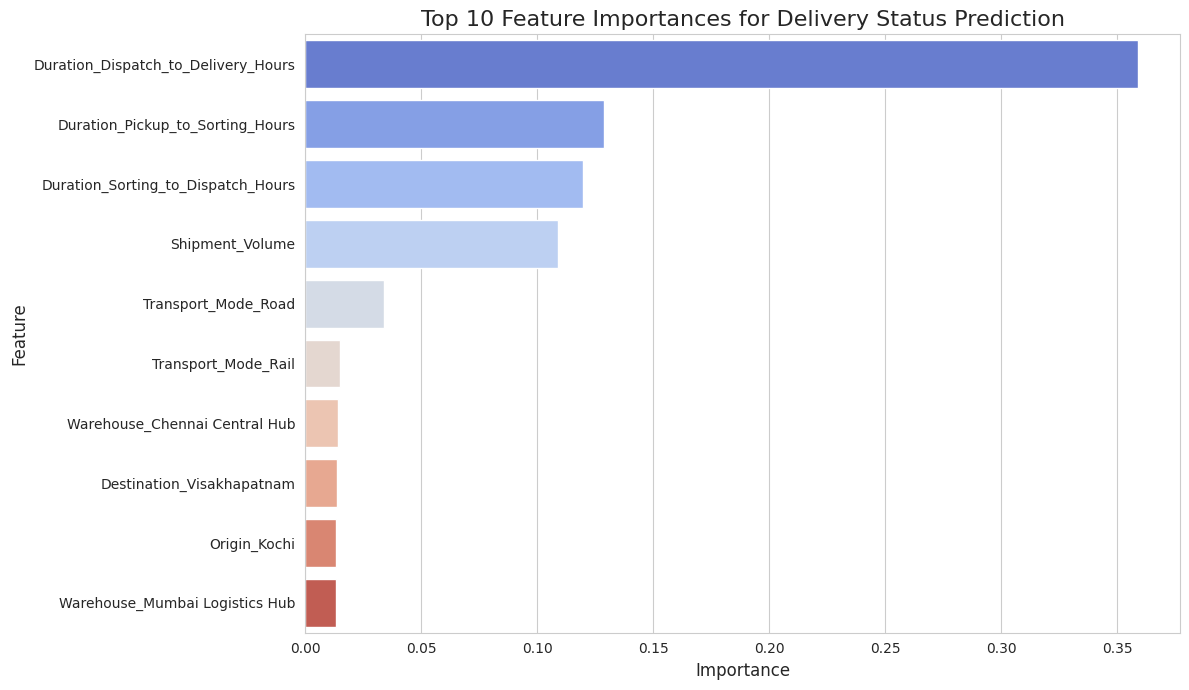

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

# Get feature importances from the trained Random Forest model
feature_importances = rf_classifier.feature_importances_

# Create a Series for better handling and sorting
feature_importance_series = pd.Series(feature_importances, index=X.columns)

# Sort feature importances in descending order
sorted_feature_importances = feature_importance_series.sort_values(ascending=False)

print("Top 10 Feature Importances:")
display(sorted_feature_importances.head(10))

# Visualize feature importances
plt.figure(figsize=(12, 7))
sns.barplot(x=sorted_feature_importances.head(10).values, y=sorted_feature_importances.head(10).index, palette='coolwarm')
plt.title('Top 10 Feature Importances for Delivery Status Prediction', fontsize=16)
plt.xlabel('Importance', fontsize=12)
plt.ylabel('Feature', fontsize=12)
plt.tight_layout()
plt.show()

### Key Insights and Practical Action Plan

Based on the comprehensive data analysis and predictive modeling, we can derive several key insights regarding the logistics supply chain and propose actionable strategies to improve efficiency and reduce delays.

#### Key Insights:

1.  **Dominant Bottleneck in Dispatch to Delivery:** The 'Dispatch to Delivery' stage consistently emerges as the longest average duration (approx. 33.7 hours), accounting for the majority of the total transit time. This suggests a primary bottleneck in the last-mile or long-haul delivery process, overshadowing initial stages like 'Pickup to Sorting' (10.5 hours) and 'Sorting to Dispatch' (5.0 hours).

2.  **High Delay Rate:** Approximately 50.4% of shipments experience delays, indicating significant inefficiencies in the current logistics operations.

3.  **High-Risk Warehouses:** 'Mumbai Logistics Hub' stands out with the highest average processing time (Pickup to Dispatch) and the highest delayed shipment rate (54.3%). 'Pune Transit Center' and 'Bengaluru Distribution Center' also show elevated metrics in both categories, pointing to localized operational challenges.

4.  **Transport Mode Performance Discrepancies:**
    *   **Air Transport** is the most efficient and reliable, with the shortest average total transit time (34.6 hours) and the lowest delayed shipment rate (20.7%).
    *   **Road Transport** is the least efficient, having the longest average total transit time (54.4 hours) and the highest delayed shipment rate (61.4%).
    *   The significant performance gap between transport modes is primarily concentrated in the 'Dispatch to Delivery' stage, where Air is considerably faster.

5.  **Shipment Volume's Moderate Impact on Processing:** There is a moderate positive correlation between `Shipment_Volume` and both sorting (0.45) and dispatch (0.37) processing times. While not a strong correlation, it indicates that larger volumes can contribute to slightly longer internal processing, potentially exacerbating delays.

6.  **Predictive Model Effectiveness:** The Random Forest Classifier achieved an accuracy of 78% in predicting `Delivery_Status`, which is a substantial improvement over the 51% baseline accuracy. This indicates that the selected features capture meaningful information about factors influencing delivery outcomes.

7.  **Key Predictive Features:** The most important features for predicting delivery status are the durations of the various stages, particularly 'Duration_Dispatch_to_Delivery_Hours', followed by 'Duration_Pickup_to_Sorting_Hours' and 'Duration_Sorting_to_Dispatch_Hours'. 'Shipment_Volume' and 'Transport_Mode_Road' are also significant predictors.

#### Practical Action Plan:

1.  **Focus on 'Dispatch to Delivery' Optimization:**
    *   **Route Optimization:** Implement advanced route optimization software for road transport to identify the most efficient delivery paths, considering traffic, road conditions, and delivery windows.
    *   **Last-Mile Solutions:** Explore and invest in innovative last-mile delivery solutions, such as local micro-fulfillment centers, partnerships with local delivery services, or drone/robotics for dense urban areas.
    *   **Driver Efficiency:** Provide training for drivers on efficient delivery practices and utilize telematics data to monitor and improve driving performance.

2.  **Targeted Interventions for High-Risk Warehouses:**
    *   **Operational Audit:** Conduct detailed operational audits at 'Mumbai Logistics Hub', 'Pune Transit Center', and 'Bengaluru Distribution Center' to identify specific bottlenecks, staffing issues, or process inefficiencies.
    *   **Process Improvement:** Implement lean Six Sigma methodologies or similar process improvement initiatives to streamline operations in these warehouses.
    *   **Technology Upgrades:** Consider investing in automation, better sorting equipment, or warehouse management systems (WMS) to enhance processing speed and accuracy.

3.  **Strategic Transport Mode Utilization:**
    *   **Promote Air Transport for Urgent/Sensitive Shipments:** Encourage the use of air transport for high-priority or time-sensitive shipments due to its superior speed and reliability.
    *   **Road Transport Efficiency for Standard Shipments:** For standard road transport, focus on optimizing routes, improving truck maintenance to reduce breakdowns, and utilizing efficient loading/unloading procedures.
    *   **Modal Shift Analysis:** Conduct a cost-benefit analysis to identify opportunities for shifting volume from road to rail or other more efficient modes where feasible, especially for inter-city long hauls.

4.  **Manage Shipment Volume Impacts:**
    *   **Load Balancing:** Implement strategies to balance shipment volumes across different warehouses and transport routes to avoid overwhelming specific nodes.
    *   **Dynamic Staffing:** Adjust staffing levels in sorting and dispatch based on predicted shipment volumes to maintain consistent processing times.

5.  **Leverage Predictive Model for Proactive Management:**
    *   **Early Warning System:** Integrate the Random Forest model into an operational dashboard to provide an early warning system for potentially delayed shipments, allowing proactive intervention.
    *   **Resource Allocation:** Use model predictions to dynamically allocate resources (e.g., extra staff, alternative transport) to shipments with a high probability of delay.
    *   **Continuous Improvement:** Regularly retrain the model with new data to ensure its accuracy and relevance, and use feature importance insights to guide ongoing operational improvements.